# Agricultural Yield Prediction — Random Forest Regression

**Target:** `yield_kg_ha`  
This notebook follows the same structure as the Linear Regression notebook: same cleaning, encoding, 80/10/10 split (`random_state=42`), evaluation helper and comparison plots. It uses the uploaded `final.csv` dataset.

Modelling:
- Random Forest Regression baseline (untuned)
- RandomizedSearchCV for hyperparameter tuning

**Changes from the Linear Regression notebook (and why):**
1. **Extra cleaning:** `final.csv` has impossible years (0 to 2124) and many misspelled or differently cased crop names, so these are fixed in Section 2.
2. **Outlier rule:** the IQR rule is applied on `log(yield)` per crop with multiplier 1.5 (Section 3), because yield is extremely right-skewed with some values in the millions.
3. **Log-transformed target:** models are trained on `log1p(yield)` using `TransformedTargetRegressor`; predictions are converted back to kg/ha, so all MAE, RMSE and R² values below are on the original kg/ha scale.
4. **No scaling:** tree models do not depend on feature scale, so `StandardScaler` is not used.

Because of the stricter cleaning, scores here are not directly comparable with the Linear Regression notebook, which was evaluated on a different set of rows.

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import difflib

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

# Keep final.csv in the same folder as this notebook
df = pd.read_csv("final.csv", low_memory=False)

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (54423, 31)


,Country,Crop,Year,Yield,Flag,temp,tmax,tmin,humidity,soil_root,...,rainfall,Unit,Note,Domain Code,Domain,Area Code (M49),Element Code,Element,Item Code (CPC),Flag Description
0,Türkiye,Sugar beet,1993,37052.1,A,15.203333333333331,40.22,-8.096666666666666,57.153333333333336,0.5266666666666667,...,384.4666666666667,kg/ha,NaN,QCL,Crops and livestock products,792.0,5412,Yield,1801.00,Official value
1,Thailand,"Other citrus fruit, n.e.c.",2010,4199.1,E,26.89333333333333,42.22666666666667,12.753333333333332,70.35000000000001,0.5800000000000001,...,1266.55,kg/ha,NaN,QCL,Crops and livestock products,764.0,5412,Yield,1329.00,Estimated value
2,Türkiye,"Other beans, green",2015,12785.5,A,15.953333333333331,41.03,-9.926666666666668,63.25333333333333,0.5833333333333334,...,515.8666666666667,kg/ha,NaN,QCL,Crops and livestock products,792.0,5412,Yield,1241.90,Official value
3,South Africa,Carrots and turnips,2020,29512.0,E,17.753333333333334,38.806666666666665,-1.07,58.50333333333333,0.5066666666666667,...,768.9333333333334,kg/ha,NaN,QCL,Crops and livestock products,710.0,5412,Yield,1251.00,Estimated value
4,Germany,"Onions and shallots, dry (excluding dehydrated)",2000,42078.1,A,9.5,32.105000000000004,-13.24,80.495,0.595,...,638.75,kg/ha,NaN,QCL,Crops and livestock products,276.0,5412,Yield,1253.02,Official value


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54423 entries, 0 to 54422
Data columns (total 31 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country           54403 non-null  object 
 1   Crop              54403 non-null  object 
 2   Year              54403 non-null  object 
 3   Yield             54203 non-null  object 
 4   Flag              54166 non-null  object 
 5   temp              54341 non-null  object 
 6   tmax              54308 non-null  object 
 7   tmin              54302 non-null  object 
 8   humidity          54306 non-null  object 
 9   soil_root         54307 non-null  object 
 10  soil_top          54305 non-null  object 
 11  precip_mm         54403 non-null  object 
 12  precip_q1         54390 non-null  object 
 13  soil_q1           54387 non-null  object 
 14  precip_q2         54387 non-null  object 
 15  soil_q2           54387 non-null  object 
 16  precip_q3         54389 non-null  object

## 2. Data cleaning

The first block keeps the cleaning approach of the earlier notebooks. The second block fixes problems specific to `final.csv`: impossible years and misspelled crop names.

In [2]:
# Drop metadata / duplicate-description columns when they exist in this dataset
drop_cols = [
    "Unit", "Note", "Domain Code", "Domain", "Area Code (M49)",
    "Element Code", "Element", "Item Code (CPC)"
]
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Rename columns to the same readable naming style as the earlier notebooks
rename_cols = {
    "Country": "country",
    "Crop": "crop",
    "Year": "year",
    "Yield": "yield_kg_ha",
    "Flag": "flag",
    "Flag Description": "flag_desc",
    "temp": "temp_mean",
    "tmax": "temp_max",
    "tmin": "temp_min"
}
df = df.rename(columns=rename_cols)

print("\nMissing values before cleaning:\n", df.isnull().sum())

# Same target/duplicate cleaning approach as the earlier notebooks
df = df.dropna(subset=["yield_kg_ha"])
df = df.drop_duplicates()

# Convert model columns to numeric where applicable (invalid entries become missing)
numeric_cols = [c for c in df.columns if c not in ["country", "crop", "flag", "flag_desc"]]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove impossible values using the same rules as before
df = df[(df["yield_kg_ha"] > 0)]
if "rainfall" in df.columns:
    df = df[df["rainfall"] >= 0]
if "humidity" in df.columns:
    df = df[df["humidity"].between(0, 100)]

# Remove rows with missing values in predictor columns, without introducing an imputer
df = df.dropna()

# Clean text fields as in the original notebooks
df["crop"] = df["crop"].str.strip()
df["country"] = df["country"].str.strip()

# rainfall and precip_mm represent the same overall precipitation measure in this file;
# retain rainfall (the name used in the original notebooks) and remove precip_mm.
if "rainfall" in df.columns and "precip_mm" in df.columns:
    if df["rainfall"].equals(df["precip_mm"]):
        df = df.drop(columns=["precip_mm"])

print("\nShape after basic cleaning:", df.shape)
display(df.head())


Missing values before cleaning:
 country         20
crop            20
year            20
yield_kg_ha    220
flag           257
temp_mean       82
temp_max       115
temp_min       121
humidity       117
soil_root      116
soil_top       118
precip_mm       20
precip_q1       33
soil_q1         36
precip_q2       36
soil_q2         36
precip_q3       34
soil_q3         28
precip_q4       34
soil_q4         30
temp_range      20
rainfall        20
flag_desc      442
dtype: int64

Shape after basic cleaning: (50713, 23)


,country,crop,year,yield_kg_ha,flag,temp_mean,temp_max,temp_min,humidity,soil_root,...,soil_q1,precip_q2,soil_q2,precip_q3,soil_q3,precip_q4,soil_q4,temp_range,rainfall,flag_desc
0,Türkiye,Sugar beet,1993.0,37052.1,A,15.203333,40.220000,-8.096667,57.153333,0.526667,...,0.640000,119.168000,0.554444,4.864000,0.437778,108.122667,0.481111,48.316667,384.466667,Official value
1,Thailand,"Other citrus fruit, n.e.c.",2010.0,4199.1,E,26.893333,42.226667,12.753333,70.350000,0.580000,...,0.452222,263.264000,0.477778,694.538667,0.681111,252.928000,0.700000,29.473333,1266.550000,Estimated value
2,Türkiye,"Other beans, green",2015.0,12785.5,A,15.953333,41.030000,-9.926667,63.253333,0.583333,...,0.776667,115.013333,0.618889,31.210667,0.455556,95.253333,0.488889,50.956667,515.866667,Official value
3,South Africa,Carrots and turnips,2020.0,29512.0,E,17.753333,38.806667,-1.070000,58.503333,0.506667,...,0.453333,166.693333,0.480000,184.122667,0.578889,233.877333,0.518889,39.876667,768.933333,Estimated value
4,Germany,"Onions and shallots, dry (excluding dehydrated)",2000.0,42078.1,A,9.500000,32.105000,-13.240000,80.495000,0.595000,...,0.656667,132.392000,0.620000,206.720000,0.536667,123.880000,0.566667,45.345000,638.750000,Official value


,country,crop,year,yield_kg_ha,flag,temp_mean,temp_max,temp_min,humidity,soil_root,...,soil_q1,precip_q2,soil_q2,precip_q3,soil_q3,precip_q4,soil_q4,temp_range,rainfall,flag_desc
0,Türkiye,Sugar beet,1993.0,37052.1,A,15.203333,40.220000,-8.096667,57.153333,0.526667,...,0.640000,119.168000,0.554444,4.864000,0.437778,108.122667,0.481111,48.316667,384.466667,Official value
1,Thailand,"Other citrus fruit, n.e.c.",2010.0,4199.1,E,26.893333,42.226667,12.753333,70.350000,0.580000,...,0.452222,263.264000,0.477778,694.538667,0.681111,252.928000,0.700000,29.473333,1266.550000,Estimated value
2,Türkiye,"Other beans, green",2015.0,12785.5,A,15.953333,41.030000,-9.926667,63.253333,0.583333,...,0.776667,115.013333,0.618889,31.210667,0.455556,95.253333,0.488889,50.956667,515.866667,Official value
3,South Africa,Carrots and turnips,2020.0,29512.0,E,17.753333,38.806667,-1.070000,58.503333,0.506667,...,0.453333,166.693333,0.480000,184.122667,0.578889,233.877333,0.518889,39.876667,768.933333,Estimated value
4,Germany,"Onions and shallots, dry (excluding dehydrated)",2000.0,42078.1,A,9.500000,32.105000,-13.240000,80.495000,0.595000,...,0.656667,132.392000,0.620000,206.720000,0.536667,123.880000,0.566667,45.345000,638.750000,Official value


In [3]:
# 2.1 Impossible years: this file contains years such as 0 and 2124
print("Rows with impossible years:", (~df["year"].between(1960, 2024)).sum())
df = df[df["year"].between(1960, 2024)]

# 2.2 Crop names contain case differences, punctuation and typos
# (e.g. "Green corn (maize)." and "Green corn (miaze)"), so one crop appears as many labels.
print("Crop labels before fixing:", df["crop"].nunique())

df["crop"] = (
    df["crop"].str.lower()
    .str.replace(r"[^a-z0-9 ]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Labels with at least 10 rows are treated as correct; rarer labels are matched
# to the closest correct label, and dropped if no close match exists.
label_counts = df["crop"].value_counts()
valid_labels = list(label_counts[label_counts >= 10].index)
valid_set = set(valid_labels)

label_map = {}
for label in label_counts.index:
    if label in valid_set:
        label_map[label] = label
    else:
        match = difflib.get_close_matches(label, valid_labels, n=1, cutoff=0.85)
        label_map[label] = match[0] if match else None

df["crop"] = df["crop"].map(label_map)
df = df.dropna(subset=["crop"])

print("Crop labels after fixing :", df["crop"].nunique())
# 2.3 Country names have the same problem (India / INDIA / iNDia ...), so normalize them
print("Country labels before fixing:", df["country"].nunique())

df["country"] = (
    df["country"]
    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")  # Türkiye -> Turkiye, España -> Espana
    .str.lower()
    .str.replace(r"[^a-z0-9 ]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# same country, different names -> one name
df["country"] = df["country"].replace({
    "turkey": "turkiye",
    "us": "united states of america",
    "usa": "united states of america",
    "u s a": "united states of america",
    "united states": "united states of america",
    "espana": "spain",
    "italia": "italy",
    "brasil": "brazil",
    "deutschland": "germany",
    "china mainland": "china",
    "pr china": "china",
})

country_counts = df["country"].value_counts()
valid_countries = list(country_counts[country_counts >= 10].index)
valid_country_set = set(valid_countries)

country_map = {}
for label in country_counts.index:
    if label in valid_country_set:
        country_map[label] = label
    else:
        match = difflib.get_close_matches(label, valid_countries, n=1, cutoff=0.85)
        country_map[label] = match[0] if match else None

df["country"] = df["country"].map(country_map)
df = df.dropna(subset=["country"])
df["country"] = df["country"].str.title()   # "india" -> "India"

print("Country labels after fixing :", df["country"].nunique())
print(sorted(df["country"].unique()))

print("Shape after extra cleaning:", df.shape)

Rows with impossible years: 207
Crop labels before fixing: 667
Crop labels after fixing : 142
Country labels before fixing: 189
Country labels after fixing : 31
Shape after extra cleaning: (50435, 23)


## 3. Outlier removal using 1.5 × IQR on log(yield)

Outliers are removed crop-wise using the target variable, as in the earlier notebooks, but on the log scale.

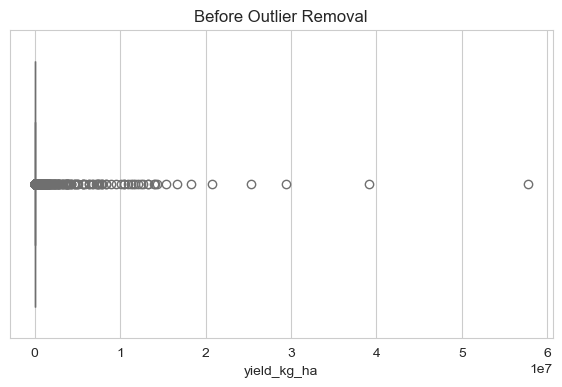

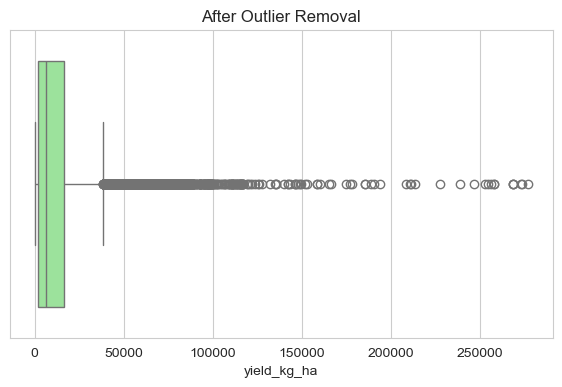

Outlier removal completed!
Shape after outlier removal: (48375, 23)


In [4]:
# Yield is heavily right-skewed (a few values are millions of kg/ha), so the IQR rule
# is applied on log(yield) for each crop. Multiplier 1.5 is the standard IQR rule.
df["log_yield"] = np.log1p(df["yield_kg_ha"])

plt.figure(figsize=(7, 4))
sns.boxplot(x=df["yield_kg_ha"], color="skyblue")
plt.title("Before Outlier Removal")
plt.show()

for crop_name in df["crop"].unique():
    crop_data = df[df["crop"] == crop_name]
    q1 = crop_data["log_yield"].quantile(0.25)
    q3 = crop_data["log_yield"].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df = df[
        (df["crop"] != crop_name) |
        (df["log_yield"].between(lower, upper))
    ]

df = df.drop(columns=["log_yield"])

plt.figure(figsize=(7, 4))
sns.boxplot(x=df["yield_kg_ha"], color="lightgreen")
plt.title("After Outlier Removal")
plt.show()

print("Outlier removal completed!")
print("Shape after outlier removal:", df.shape)

## 4. Encoding

`flag` and `flag_desc` are descriptive metadata, so they are excluded from the predictors as in the earlier notebooks. Crop and country are one-hot encoded using pandas.

In [5]:
clean_df = df.copy()

model_df = df.drop(
    columns=[c for c in ["flag", "flag_desc"] if c in df.columns]
)

model_df = pd.get_dummies(
    model_df,
    columns=["crop", "country"],
    drop_first=True,
    dtype=int
)

print("Model data shape:", model_df.shape)
display(model_df.head())

Model data shape: (48375, 190)


,year,yield_kg_ha,temp_mean,temp_max,temp_min,humidity,soil_root,soil_top,precip_mm,precip_q1,...,country_South Africa,country_Spain,country_T Rkiye,country_Thailand,country_Turkey,country_Turkiye,country_U S A,country_United States Of America,country_Us,country_Usa
0,1993.0,37052.1,15.203333,40.220000,-8.096667,57.153333,0.526667,0.430000,384.466667,153.013333,...,0,0,1,0,0,0,0,0,0,0
1,2010.0,4199.1,26.893333,42.226667,12.753333,70.350000,0.580000,0.553333,1266.550000,45.498667,...,0,0,0,1,0,0,0,0,0,0
2,2015.0,12785.5,15.953333,41.030000,-9.926667,63.253333,0.583333,0.523333,515.866667,277.856000,...,0,0,1,0,0,0,0,0,0,0
3,2020.0,29512.0,17.753333,38.806667,-1.070000,58.503333,0.506667,0.473333,768.933333,184.933333,...,1,0,0,0,0,0,0,0,0,0
4,2000.0,42078.1,9.500000,32.105000,-13.240000,80.495000,0.595000,0.620000,638.750000,175.256000,...,0,0,0,0,0,0,0,0,0,0


## 5. Exploratory Data Analysis

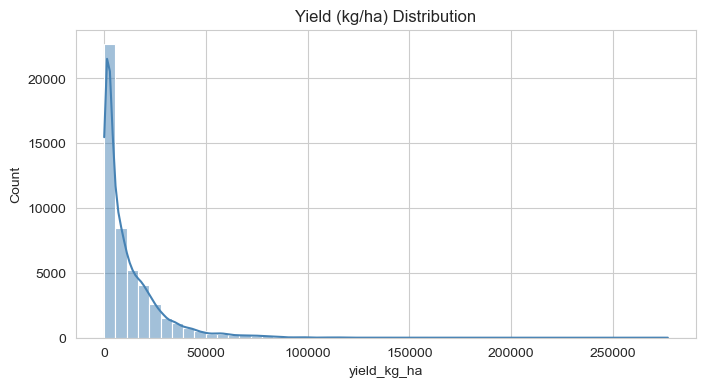

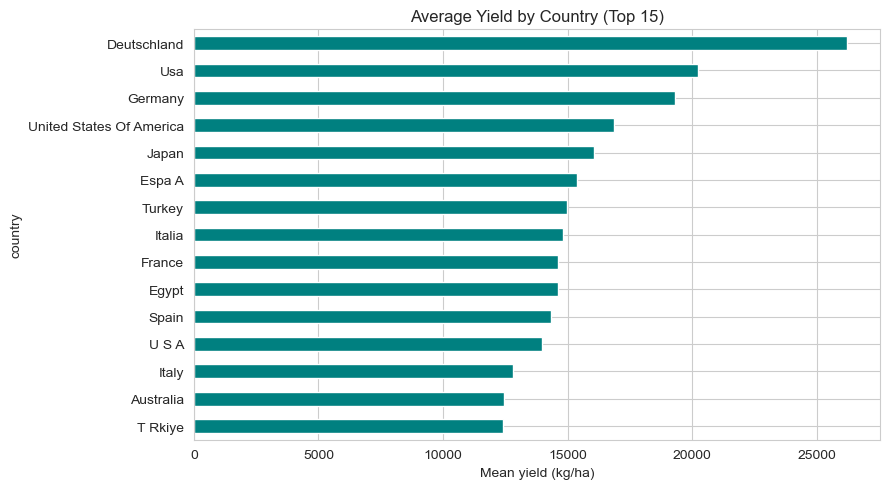

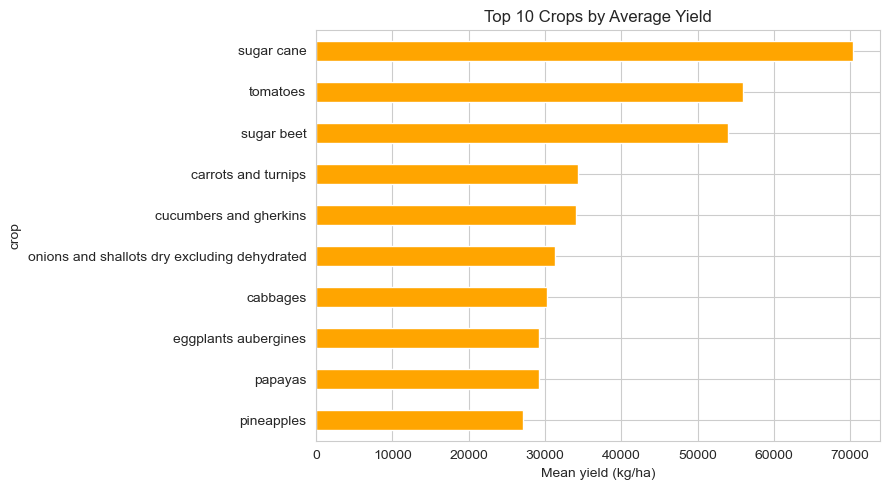

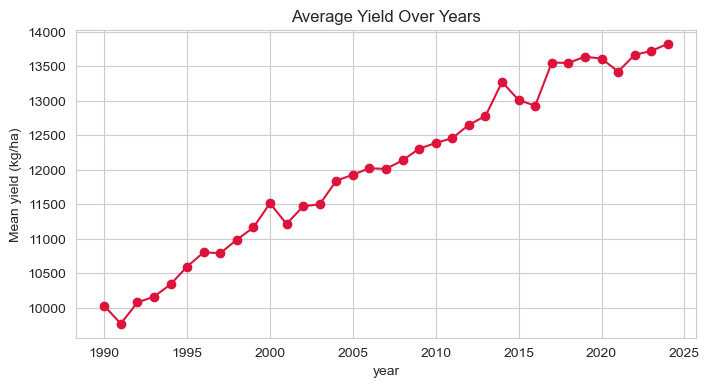

In [6]:
# 5.1 Yield distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["yield_kg_ha"], bins=50, kde=True, color="steelblue")
plt.title("Yield (kg/ha) Distribution")
plt.show()

# 5.2 Average yield by country (top 15)
plt.figure(figsize=(9, 5))
df.groupby("country")["yield_kg_ha"].mean().sort_values().tail(15).plot(kind="barh", color="teal")
plt.xlabel("Mean yield (kg/ha)")
plt.title("Average Yield by Country (Top 15)")
plt.tight_layout()
plt.show()

# 5.3 Top 10 crops by average yield
plt.figure(figsize=(9, 5))
df.groupby("crop")["yield_kg_ha"].mean().sort_values(ascending=False).head(10)[::-1].plot(kind="barh", color="orange")
plt.xlabel("Mean yield (kg/ha)")
plt.title("Top 10 Crops by Average Yield")
plt.tight_layout()
plt.show()

# 5.4 Yield trend over years
df.groupby("year")["yield_kg_ha"].mean().plot(marker="o", figsize=(8, 4), color="crimson")
plt.ylabel("Mean yield (kg/ha)")
plt.title("Average Yield Over Years")
plt.show()

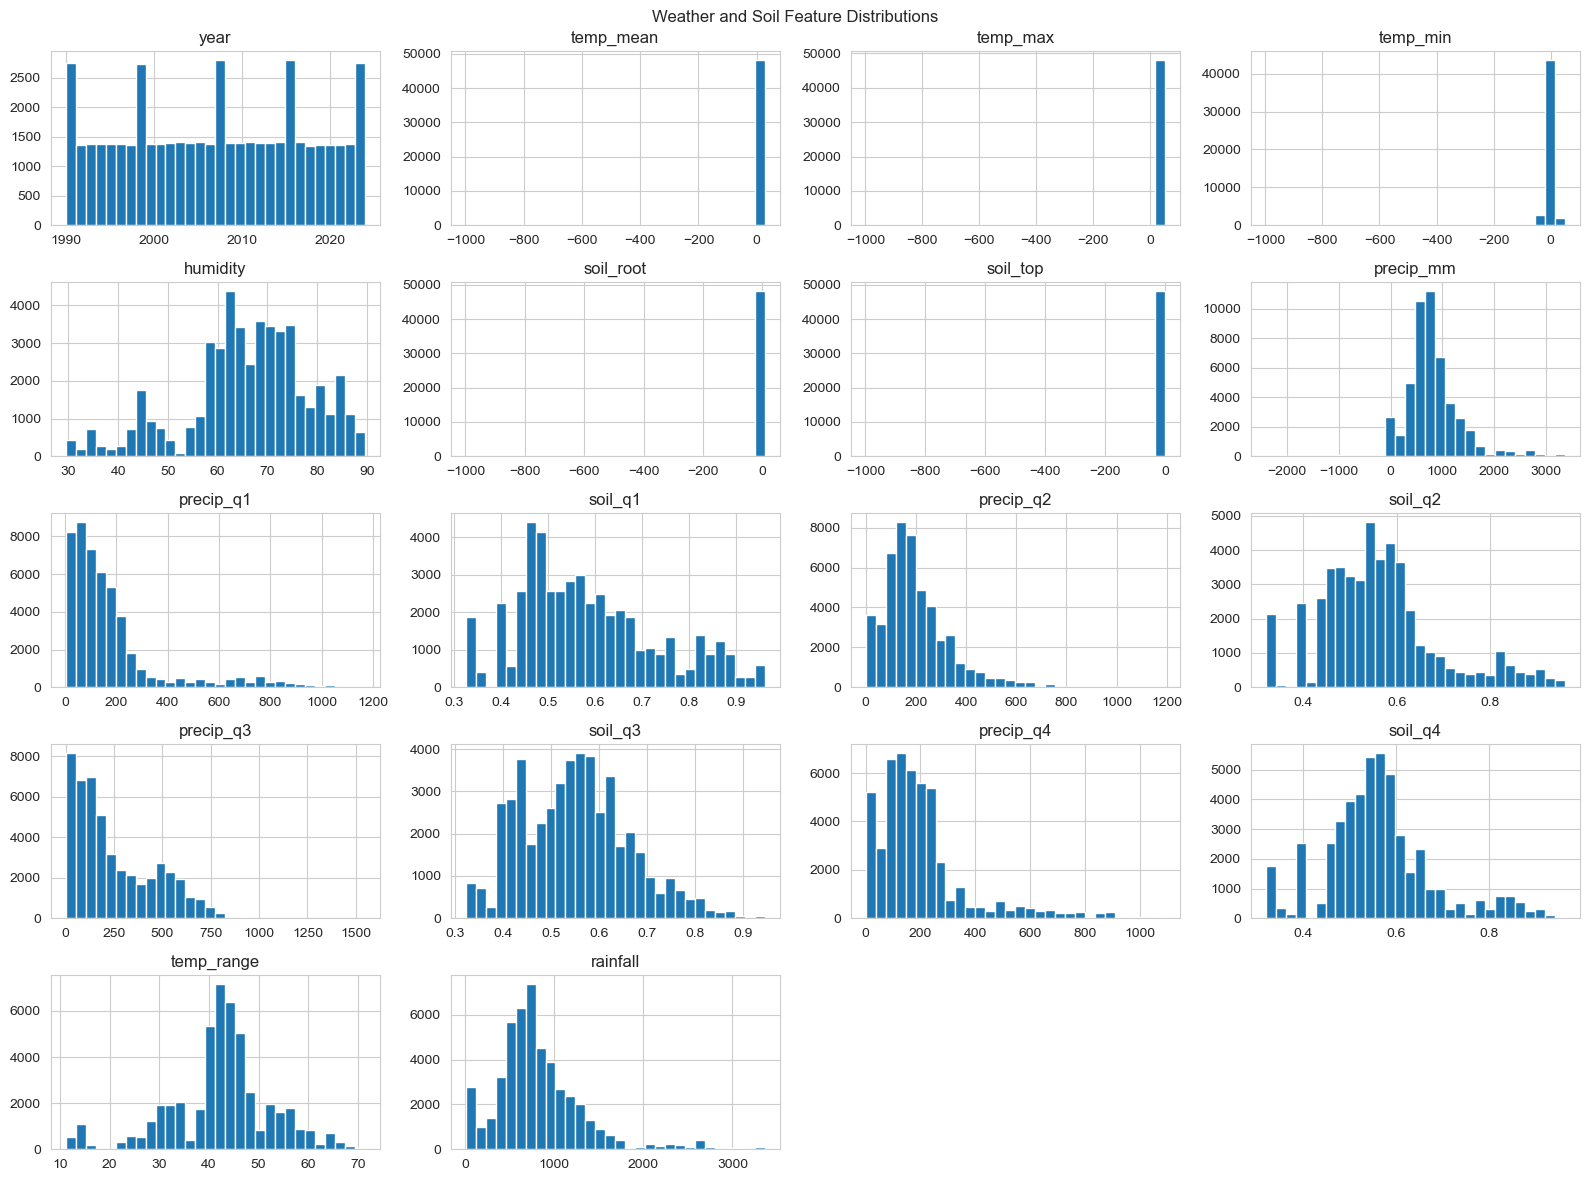

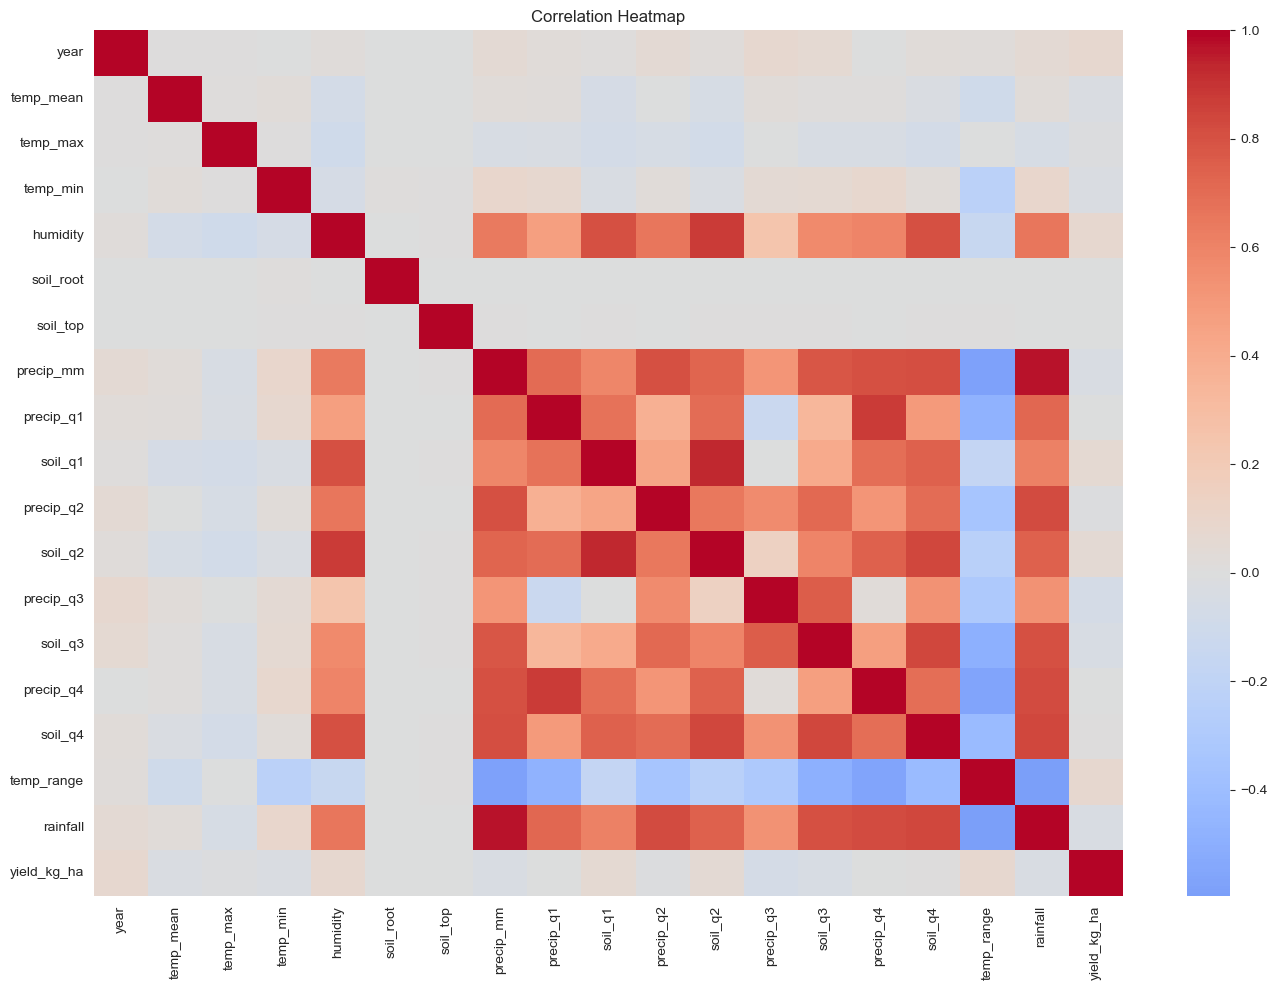

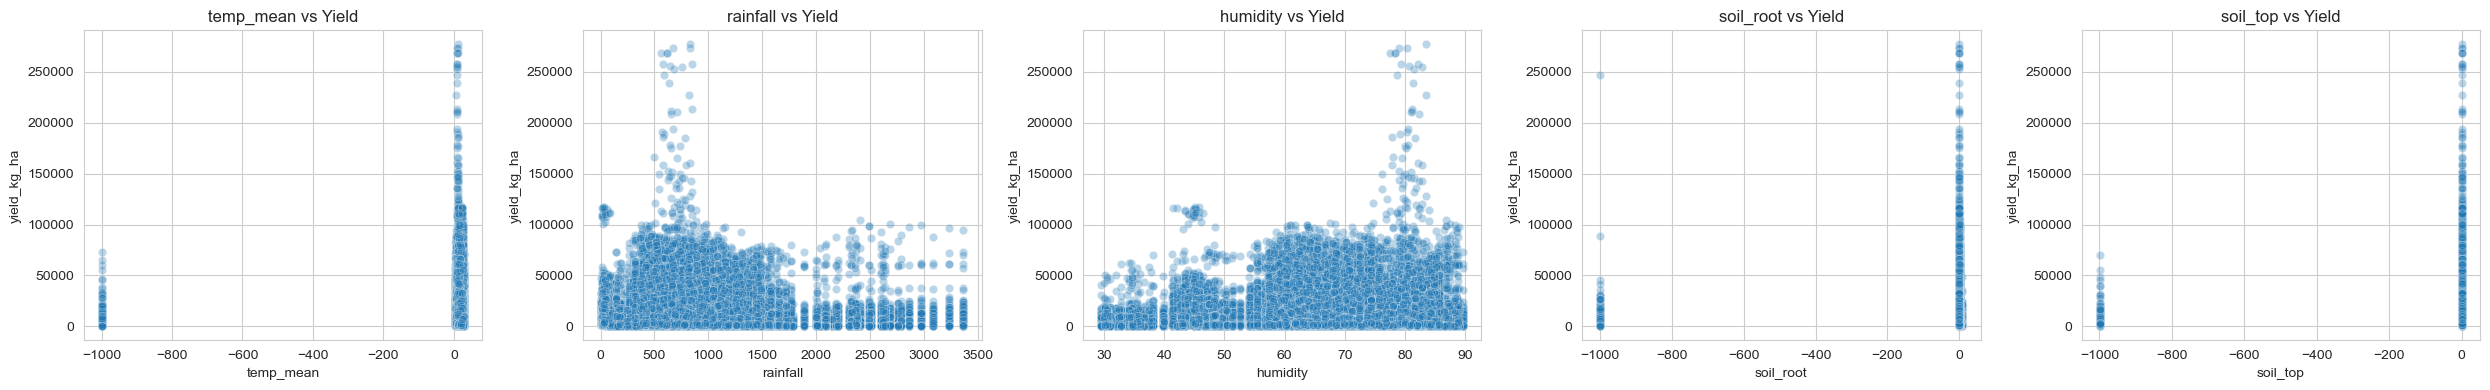

In [7]:
# 5.5 Distributions of numeric weather/soil predictors
numeric_predictors = [
    c for c in df.select_dtypes(include=np.number).columns
    if c != "yield_kg_ha"
]
df[numeric_predictors].hist(bins=30, figsize=(16, 12))
plt.suptitle("Weather and Soil Feature Distributions")
plt.tight_layout()
plt.show()

# 5.6 Correlation heatmap
corr_cols = numeric_predictors + ["yield_kg_ha"]
plt.figure(figsize=(14, 10))
sns.heatmap(df[corr_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 5.7 Selected weather/soil features vs yield
selected_features = [c for c in ["temp_mean", "rainfall", "humidity", "soil_root", "soil_top"] if c in df.columns]
fig, axes = plt.subplots(1, len(selected_features), figsize=(5 * len(selected_features), 4))
if len(selected_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, selected_features):
    sns.scatterplot(data=df, x=feature, y="yield_kg_ha", alpha=0.3, ax=ax)
    ax.set_title(f"{feature} vs Yield")
plt.tight_layout()
plt.show()

## 6. Train-validation-test split

The split is 80% training, 10% validation and 10% testing with `random_state=42`. Tree models do not need feature scaling.

In [8]:
X = model_df.drop(columns=["yield_kg_ha"])
y = model_df["yield_kg_ha"]

# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Display dataset dimensions
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

X_train: (38700, 189)
X_val  : (4837, 189)
X_test : (4838, 189)
y_train: (38700,)
y_val  : (4837,)
y_test : (4838,)


## 7. Evaluation helper

In [9]:
def evaluate_model(model_name, y_train, train_pred,
                   y_val, val_pred, y_test, test_pred):

    results = []

    datasets = [
        ("Training", y_train, train_pred),
        ("Validation", y_val, val_pred),
        ("Testing", y_test, test_pred)
    ]

    for dataset_name, y_true, y_pred in datasets:
        mae = mean_absolute_error(y_true, y_pred)
        rmse = mean_squared_error(y_true, y_pred) ** 0.5
        r2 = r2_score(y_true, y_pred)

        print(f"{model_name} - {dataset_name}")
        print("MAE  :", round(mae, 2))
        print("RMSE :", round(rmse, 2))
        print("R2   :", round(r2, 4))
        print("-" * 45)

        results.append({
            "Model": model_name,
            "Dataset": dataset_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return results

## 8. Random Forest baseline (untuned)

`TransformedTargetRegressor` trains the forest on `log1p(yield)` and returns predictions in kg/ha. `max_features=0.3` means each split looks at 30% of the features, which is much faster than the default when there are hundreds of one-hot columns.

Random Forest (untuned) - Training
MAE  : 603.98
RMSE : 1650.48
R2   : 0.9891
---------------------------------------------
Random Forest (untuned) - Validation
MAE  : 1468.95
RMSE : 3186.04
R2   : 0.9554
---------------------------------------------
Random Forest (untuned) - Testing
MAE  : 1493.6
RMSE : 3762.2
R2   : 0.9409
---------------------------------------------


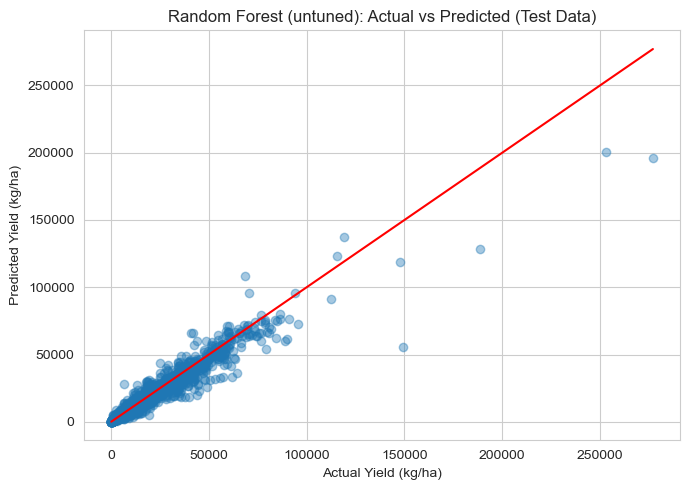

,Model,Dataset,MAE,RMSE,R2
0,Random Forest (untuned),Training,603.975238,1650.475750,0.989125
1,Random Forest (untuned),Validation,1468.950965,3186.040772,0.955409
2,Random Forest (untuned),Testing,1493.597700,3762.202349,0.940872


In [10]:
results = []

rf_model = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        n_estimators=100, max_features=0.3, random_state=42, n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)
rf_model.fit(X_train, y_train)

# Predictions on all three datasets
y_train_pred_rf = rf_model.predict(X_train)
y_val_pred_rf = rf_model.predict(X_val)
y_test_pred_rf = rf_model.predict(X_test)

# Evaluate Random Forest
results.extend(evaluate_model(
    "Random Forest (untuned)",
    y_train, y_train_pred_rf,
    y_val, y_val_pred_rf,
    y_test, y_test_pred_rf
))

# Actual vs Predicted plot (Test Dataset)
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred_rf, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.title("Random Forest (untuned): Actual vs Predicted (Test Data)")
plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

## 9. Hyperparameter tuning with RandomizedSearchCV

- `n_estimators`: number of trees
- `max_depth`: maximum depth of each tree
- `min_samples_leaf`: minimum rows in a leaf
- `max_features`: fraction of features examined at each split

A random forest is slow to fit, so RandomizedSearchCV (a sample of the combinations) is used instead of a full grid. The best combination is selected using 3-fold cross-validation on the training set only, scored with R² on the original kg/ha scale. The test set is not used during tuning. This cell takes several minutes.

Random Forest RandomizedSearch best parameters: {'regressor__n_estimators': 150, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.3, 'regressor__max_depth': None}
Random Forest best CV R2: 0.925


,params,mean_test_score,rank_test_score
5,"{'regressor__n_estimators': 150, 'regressor__m...",0.925024,1
0,"{'regressor__n_estimators': 100, 'regressor__m...",0.923439,2
2,"{'regressor__n_estimators': 100, 'regressor__m...",0.920525,3
4,"{'regressor__n_estimators': 150, 'regressor__m...",0.915360,4
3,"{'regressor__n_estimators': 100, 'regressor__m...",0.790520,5
1,"{'regressor__n_estimators': 100, 'regressor__m...",0.753783,6


Random Forest + RandomizedSearchCV - Training
MAE  : 782.79
RMSE : 2110.48
R2   : 0.9822
---------------------------------------------
Random Forest + RandomizedSearchCV - Validation
MAE  : 1486.46
RMSE : 3237.27
R2   : 0.954
---------------------------------------------
Random Forest + RandomizedSearchCV - Testing
MAE  : 1527.6
RMSE : 3860.27
R2   : 0.9377
---------------------------------------------


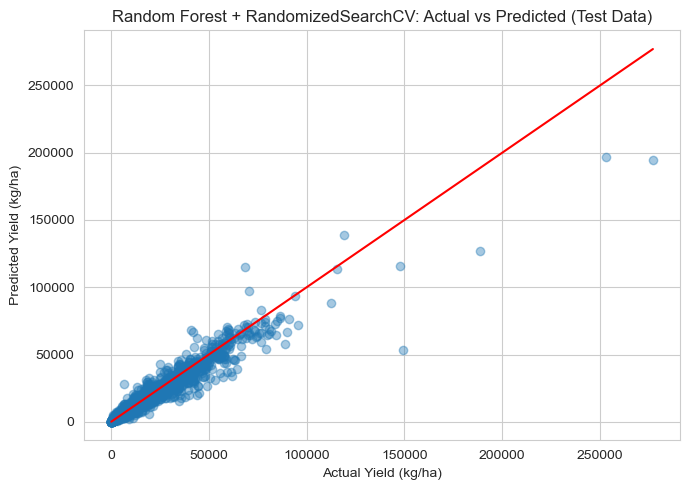

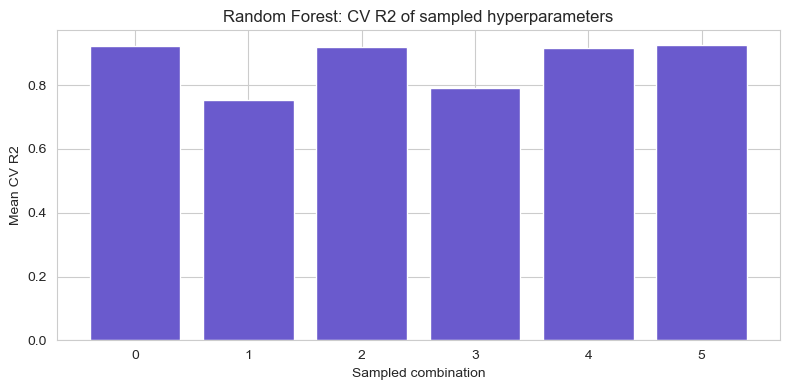

,Model,Dataset,MAE,RMSE,R2
0,Random Forest (untuned),Training,603.975238,1650.475750,0.989125
1,Random Forest (untuned),Validation,1468.950965,3186.040772,0.955409
2,Random Forest (untuned),Testing,1493.597700,3762.202349,0.940872
3,Random Forest + RandomizedSearchCV,Training,782.790709,2110.480884,0.982218
4,Random Forest + RandomizedSearchCV,Validation,1486.459125,3237.265694,0.953964
5,Random Forest + RandomizedSearchCV,Testing,1527.599062,3860.271897,0.937749


In [11]:
rf_param_dist = {
    "regressor__n_estimators": [100, 150],
    "regressor__max_depth": [None, 30],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.2, 0.3]
}

rf_random = RandomizedSearchCV(
    estimator=TransformedTargetRegressor(
        regressor=RandomForestRegressor(random_state=42, n_jobs=-1),
        func=np.log1p,
        inverse_func=np.expm1
    ),
    param_distributions=rf_param_dist,
    n_iter=6,
    scoring="r2",
    cv=3,
    random_state=42,
    n_jobs=1
)

rf_random.fit(X_train, y_train)

print("Random Forest RandomizedSearch best parameters:", rf_random.best_params_)
print("Random Forest best CV R2:", round(rf_random.best_score_, 4))

# All sampled combinations
cv_table = pd.DataFrame(rf_random.cv_results_)[["params", "mean_test_score", "rank_test_score"]]
display(cv_table.sort_values("rank_test_score"))

# Predictions on all three datasets
y_train_pred_rf_random = rf_random.predict(X_train)
y_val_pred_rf_random = rf_random.predict(X_val)
y_test_pred_rf_random = rf_random.predict(X_test)

# Evaluation
results.extend(evaluate_model(
    "Random Forest + RandomizedSearchCV",
    y_train, y_train_pred_rf_random,
    y_val, y_val_pred_rf_random,
    y_test, y_test_pred_rf_random
))

# Actual vs Predicted plot (Test Dataset)
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred_rf_random, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.title("Random Forest + RandomizedSearchCV: Actual vs Predicted (Test Data)")
plt.tight_layout()
plt.show()

# CV R2 of every sampled combination
plt.figure(figsize=(8, 4))
plt.bar(range(len(cv_table)), cv_table["mean_test_score"], color="slateblue")
plt.xlabel("Sampled combination")
plt.ylabel("Mean CV R2")
plt.title("Random Forest: CV R2 of sampled hyperparameters")
plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

## 10. Compare all models

,Model,Dataset,MAE,RMSE,R2
0,Random Forest (untuned),Training,603.975238,1650.475750,0.989125
1,Random Forest (untuned),Validation,1468.950965,3186.040772,0.955409
2,Random Forest (untuned),Testing,1493.597700,3762.202349,0.940872
3,Random Forest + RandomizedSearchCV,Training,782.790709,2110.480884,0.982218
4,Random Forest + RandomizedSearchCV,Validation,1486.459125,3237.265694,0.953964
5,Random Forest + RandomizedSearchCV,Testing,1527.599062,3860.271897,0.937749


,Model,Dataset,MAE,RMSE,R2
1,Random Forest (untuned),Validation,1468.950965,3186.040772,0.955409
4,Random Forest + RandomizedSearchCV,Validation,1486.459125,3237.265694,0.953964


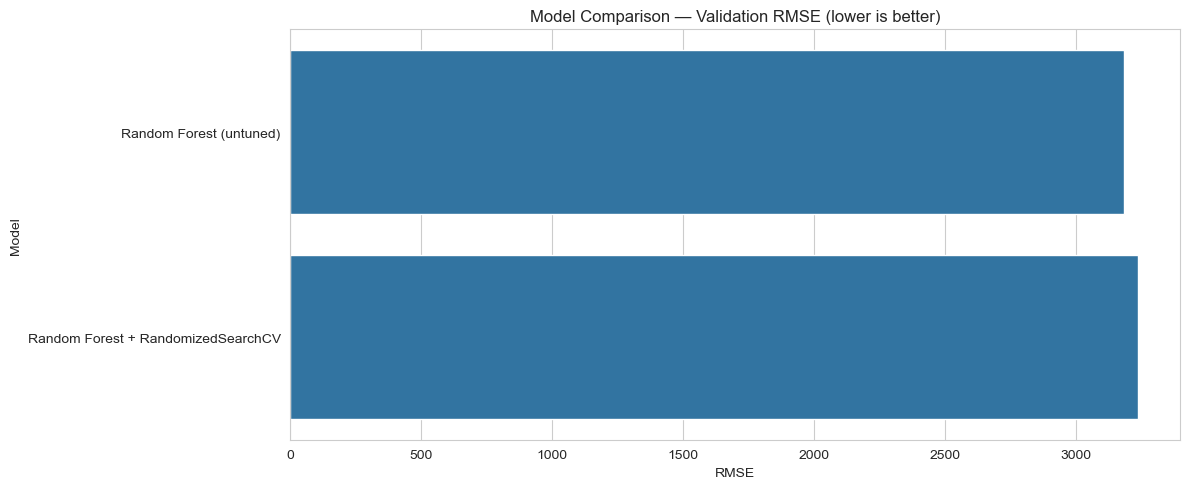

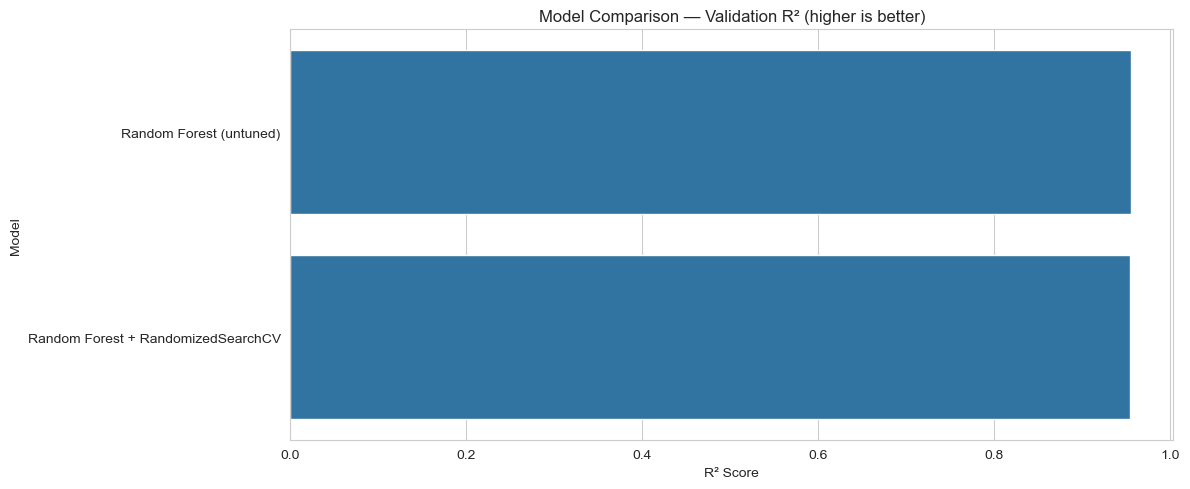

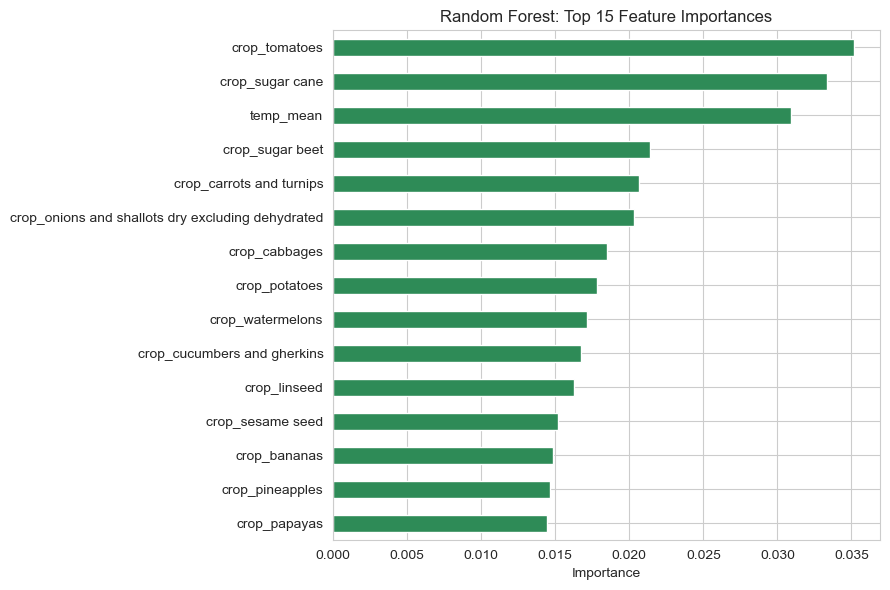

In [12]:
# Create results DataFrame
results_df = pd.DataFrame(results)

# Display all results
display(results_df)

# Select validation results only
val_results = results_df[
    results_df["Dataset"] == "Validation"
].copy()

# Sort models by RMSE (lower is better)
val_results = val_results.sort_values("RMSE")

display(val_results)


# ---------------- RMSE COMPARISON ----------------

plt.figure(figsize=(12, 5))

sns.barplot(
    data=val_results,
    x="RMSE",
    y="Model"
)

plt.title("Model Comparison — Validation RMSE (lower is better)")
plt.xlabel("RMSE")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


# ---------------- R2 COMPARISON ----------------

plt.figure(figsize=(12, 5))

r2_results = val_results.sort_values("R2", ascending=False)

sns.barplot(
    data=r2_results,
    x="R2",
    y="Model"
)

plt.title("Model Comparison — Validation R² (higher is better)")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


# ---------------- TOP 15 FEATURE IMPORTANCES ----------------

best_rf = rf_random.best_estimator_.regressor_

importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
plt.figure(figsize=(9, 6))
importances.sort_values().tail(15).plot(kind="barh", color="seagreen")
plt.xlabel("Importance")
plt.title("Random Forest: Top 15 Feature Importances")
plt.tight_layout()
plt.show()

## 11. Final Notes – Random Forest
- The dataset was split into 80% training, 10% validation, and 10% testing.
- Cleaning was extended for this dataset: impossible years were removed and misspelled crop names were merged, because `final.csv` contains both problems.
- Outliers were removed per crop with the IQR rule on log(yield). This removes extreme yield values, so scores apply to the cleaned data and are not directly comparable with the Linear Regression notebook.
- The model was trained on log1p(yield) and evaluated on the original kg/ha scale using MAE, RMSE and R².
- RandomizedSearchCV tuned `n_estimators`, `max_depth`, `min_samples_leaf` and `max_features` using 3-fold cross-validation on the training data only; the test set was kept separate for the final evaluation.
- Training and validation performance were compared to identify possible overfitting or underfitting.

Final objective: Evaluate how effectively a tuned Random Forest predicts agricultural yield using the available environmental and agricultural features.

In [13]:
import joblib

# Select the best tuned Random Forest model
final_model = rf_random.best_estimator_

# Save the feature names in the exact training order
model_columns = X_train.columns.tolist()

# Save the trained model
joblib.dump(
    final_model,
    "agricultural_yield_model.pkl"
)

# Save the model feature columns
joblib.dump(
    model_columns,
    "model_columns.pkl"
)

print("Model saved successfully!")
print("Feature columns saved successfully!")
print("Number of features:", len(model_columns))

Model saved successfully!
Feature columns saved successfully!
Number of features: 189
